In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [ ]:
# add a funtion to help us visulaize the operations that we are going to do
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:
# Add a wrapper class
class Value:
  def __init__(self,data,operation="",children=(),label=""):
    self.data=data
    self._op=operation
    self._prev=set(children)
    self.label=label
    self.grad=0
    self._backward =lambda : None


  def __repr__(self):
    return f"Value(data={self.data})"


  def __add__(self,other):
    other =other if isinstance(other,Value) else Value(other)
    output=Value(data=self.data+other.data
                 ,operation="+",
                 children=(self,other)
                 )
    def backward ():
      self.grad+=output.grad*1.0
      other.grad+=output.grad*1.0
    output._backward=backward
    return output


  def __radd__(self,other):
    return self+other


  def __mul__(self,other):
    other =other if isinstance(other,Value) else Value(other)
    output=Value(data=self.data*other.data
                 ,operation="*",
                 children=(self,other)
                 )
    def backward ():
      self.grad+=output.grad*other.data
      other.grad+=output.grad*self.data
    output._backward=backward
    return output


  def __rmul__(self,other):
    return self*other


  def __pow__(self,other):
    assert isinstance(other,(int,float)) , "only supporting int/float powers for now"
    output=Value(data=self.data**other
                 ,children=(self,)
                 ,operation=f'{other}'
                 )
    def backward ():
      self.grad+=output.grad*other*(self.data**(other-1))
    output._backward=backward
    return output



  def __truediv__(self,other):
    other =other if isinstance(other,Value) else Value(other)
    output=self*other**-1
    return output


  def __neg__(self):
     output = Value(-self.data, children=(self,), operation="neg")
     def backward():
        self.grad += output.grad * -1
     output._backward = backward
     return output


  def __sub__(self,other):
     other =other if isinstance(other,Value) else Value(other)
     output=self+(-other)
     return output


  def exp (self):
     x=self.data
     output=Value(math.exp(x),children=(self,),operation="exp")
     def backward():
      self.grad+=output.grad*math.exp(x)
     output._backward=backward
     return output


  def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()




  def tanh(self):
      output=Value(data=math.tanh(self.data),children=(self,),operation="tanh")
      def backward():
        self.grad+=(1-math.tanh(self.data)**2)*output.grad
      output._backward=backward
      return output







In [ ]:
a=Value(data=5)
b=Value(data=6)
c=a+b
c**=2
c/=4
f=Value(data=3)
g=c*f
g-=5
m=2*g
print(m)


Value(data=171.5)


In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

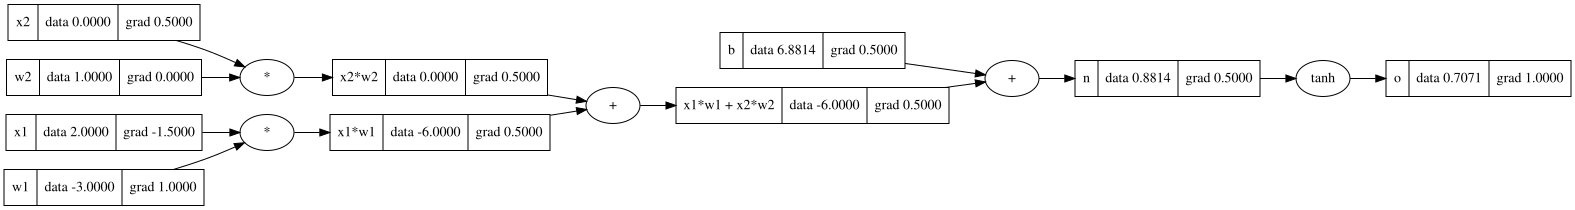

In [ ]:
draw_dot(o)

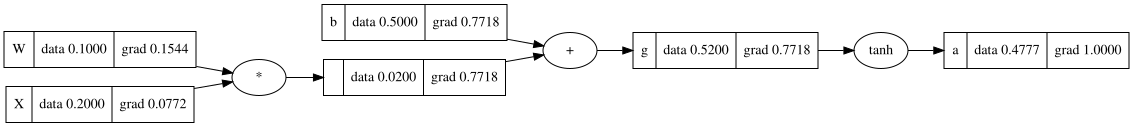

In [ ]:
w=Value(data=0.1,label="W")
x=Value(data=0.2,label="X")
b=Value(data=0.5,label="b")
g=w*x+b
g.label="g"
a=g.tanh()
a.label="a"
a.backward()
draw_dot(a)

In [ ]:
np.random.seed(42)
class neuron:
  def __init__(self,nin):
    self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
    self.b=Value(np.random.uniform(-1,1))
  def __call__(self,x):
    z= sum([wi*xi for wi,xi in zip(self.w,x)])+self.b
    output=z.tanh()
    return output
  def parameters(self):
    return self.w+[self.b]


class layer:
  def __init__(self,nin,nout):
    self.neurons=[neuron(nin)for _ in range(nout)]
  def __call__(self,x) :
    outputs=[n(x) for n in self.neurons  ]
    return outputs[0] if len(outputs)==1 else outputs
  def parameters(self):
   return  [parameter for neuron in self.neurons for parameter in neuron.parameters()]


class MLP:
  def __init__(self,nin,nouts) :
    self.size=[nin]+nouts
    self.layers=[layer(self.size[i],self.size[i+1])for i in range(len(self.size)-1)]
  def __call__(self,x) :
    for layer in self.layers:
      x=layer(x)
    return x
  def paramters (self):
    return [parameters for layer in self.layers for parameters in layer.parameters()]









In [ ]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

In [ ]:
neural_network=MLP(3,[4,5,2,1])
min_loss=1000000000
bestmodel=None
for k in range(20000):
  #forward pass
  ypred = [neural_network(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
  if loss.data<min_loss:
    min_loss=loss.data
    bestmodel=neural_network
  if (k+1)%100==0:
    print(f"epoch:{k+1}: loss={loss}")
  for parameter in neural_network.paramters():
    parameter.grad=0
  loss.backward()
  for parameter in neural_network.paramters():
    parameter.data-=parameter.grad*0.1





epoch:100: loss=Value(data=0.003977656791424801)
epoch:200: loss=Value(data=0.0018784690493106734)
epoch:300: loss=Value(data=0.00121948355735489)
epoch:400: loss=Value(data=0.0008997055503489334)
epoch:500: loss=Value(data=0.0007115043320864517)
epoch:600: loss=Value(data=0.0005877710357804014)
epoch:700: loss=Value(data=0.0005003324321201155)
epoch:800: loss=Value(data=0.0004353162027856959)
epoch:900: loss=Value(data=0.00038510796896984076)
epoch:1000: loss=Value(data=0.0003451840001467461)
epoch:1100: loss=Value(data=0.0003126893639727247)
epoch:1200: loss=Value(data=0.00028573428761625465)
epoch:1300: loss=Value(data=0.0002630185722957373)
epoch:1400: loss=Value(data=0.00024361858911117192)
epoch:1500: loss=Value(data=0.0002268603218077654)
epoch:1600: loss=Value(data=0.00021224048499636448)
epoch:1700: loss=Value(data=0.00019937575238091745)
epoch:1800: loss=Value(data=0.00018796907060706698)
epoch:1900: loss=Value(data=0.0001777867112123696)
epoch:2000: loss=Value(data=0.0001686

In [ ]:
ypred = [bestmodel(x) for x in xs]

In [ ]:
ypred

[Value(data=0.9980200987610633),
 Value(data=-0.9983041008939826),
 Value(data=-0.9976770587359866),
 Value(data=0.9980164615521486)]